# Tox21 Applications: which compounds look unusual?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/04_Applications/notebooks/TD3_tox21_solution.ipynb)

Foundations and Evaluation predicted an assay class. Here we ask a different
question: which compounds have unusual combinations of the same eight
descriptors? An outlier is unusual relative to a reference group.
A flag asks for closer review; it is not a prediction of assay activity.

All three Tox21 practicals use SR-MMP, an assay concerning
mitochondrial membrane potential. Active means a positive result
in this assay; Inactive means a negative result. Neither label is
an overall judgement about human toxicity or safety.

All code is supplied. Run the cells from top to bottom with their ▶ buttons.
Read the explanation above each cell and inspect its output. To answer a
question, double-click its Your answer text cell and write in words.

Click Open in Colab above to start this notebook. Use the standard CPU runtime.

Instructor copy: suggested answers are included.

## 1. Look at the compounds

Each sample is one compound record with a chemical structure and
assay results. A feature is a number describing that structure; the
recorded assay label is kept separate from the features.

First install RDKit, which reads structures, draws them and calculates
molecular properties. The version is fixed so the calculations stay consistent.

In [1]:
%pip -q install rdkit==2025.9.6

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\robbi\.codex\visualizations\2026\10\15\01a13f3a-3ab4-7bb3-9bfa-299d8bf73b96\strawberry-runtime\Scripts\python.exe -m pip install --upgrade pip


Load the tools: `pd` works with tables and `plt` draws plots.
`Chem` reads structures, `Draw` draws them and `Descriptors` calculates
their properties. The last line hides RDKit diagnostics; unreadable
structures are counted explicitly below.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw
from sklearn.model_selection import train_test_split

from sklearn.ensemble import IsolationForest
RDLogger.DisableLog("rdApp.*")

Read the public Tox21 file used by DeepChem. Each row is a compound record.
The file contains 12 assay columns; we use SR-MMP throughout the series.
`mol_id` identifies the source record and `smiles` describes its structure
as text. In SR-MMP, `1` means Active, `0` means Inactive and `NaN` means
no usable recorded result. Show these columns for the first five records.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
raw_data = pd.read_csv(DATA_URL)
print("Source records:", len(raw_data))
raw_data[["mol_id", "smiles", "SR-MMP"]].head()

Source records: 7831


,mol_id,smiles,SR-MMP
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0


A missing result is unknown, not Inactive. `dropna` keeps records with
an SR-MMP result and a structure string, leaving 5,810 records.

In [4]:
data = raw_data.dropna(subset=["SR-MMP", "smiles"]).copy()
print("Records with a result and structure string:", len(data))

Records with a result and structure string: 5810


`map` applies the structure-reading tool to each string. RDKit cannot
read six structures in this labelled subset. Count them and leave them
out, keeping 5,804 records. `~` means “not”.

In [5]:
data["molecule"] = data["smiles"].map(Chem.MolFromSmiles)
readable = data["molecule"].notna()
print("Structures that could not be read:", (~readable).sum())
data = data.loc[readable].copy()
print("Records kept:", len(data))

Structures that could not be read: 6
Records kept: 5804


### Draw four example compounds

Draw the first four retained structures, with their source IDs underneath.
These are the structures represented by the SMILES strings in the table.
A drawing shows the recorded structure; it does not establish assay activity.
`molsPerRow=2` places two structures on each row.

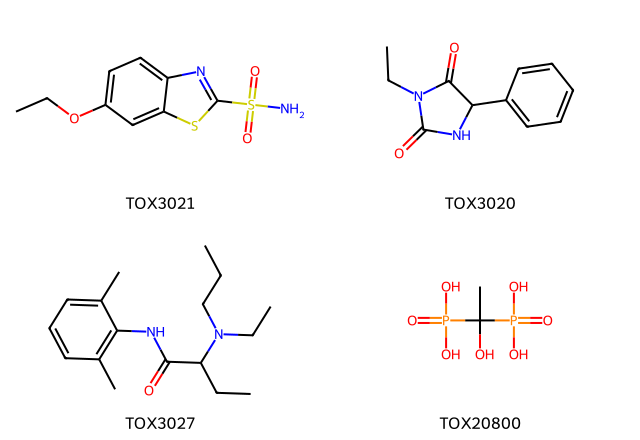

In [6]:
Draw.MolsToGridImage(
    data["molecule"].head(4).tolist(), molsPerRow=2,
    legends=data["mol_id"].head(4).tolist(), subImgSize=(320, 220)
)

## 2. Describe each compound with eight numbers

Calculate eight features from each retained structure. These descriptors
summarise properties such as size, hydrogen bonding and predicted
partitioning. The experimental SR-MMP result is kept separate.

| Feature | Meaning |
|---|---|
| Mass | Calculated molecular weight (g/mol) |
| LogP | Predicted octanol/water partition coefficient, on a log scale |
| H_donors | Number of hydrogen-bond donors |
| H_acceptors | Number of hydrogen-bond acceptors |
| Polar_area | Calculated topological polar surface area (Å²) |
| Rotatable_bonds | Number of rotatable bonds |
| Aromatic_rings | Number of aromatic rings |
| Heavy_atoms | Number of atoms other than hydrogen |

Each `map` below applies one named calculation to every molecule.
The same eight calculations are used throughout the Tox21 series.

In [7]:
features = pd.DataFrame(index=data.index)
features["Mass"] = data["molecule"].map(Descriptors.MolWt)
features["LogP"] = data["molecule"].map(Descriptors.MolLogP)
features["H_donors"] = data["molecule"].map(Descriptors.NumHDonors)
features["H_acceptors"] = data["molecule"].map(Descriptors.NumHAcceptors)
features["Polar_area"] = data["molecule"].map(Descriptors.TPSA)
features["Rotatable_bonds"] = data["molecule"].map(Descriptors.NumRotatableBonds)
features["Aromatic_rings"] = data["molecule"].map(Descriptors.NumAromaticRings)
features["Heavy_atoms"] = data["molecule"].map(Descriptors.HeavyAtomCount)

The reference label is the assay class recorded in the dataset. Replace
0 and 1 with their class names. The counts show that Inactive is much
more common than Active; we keep these unequal class sizes.

In [8]:
labels = data["SR-MMP"].map({0: "Inactive", 1: "Active"})
print(labels.value_counts())

SR-MMP
Inactive    4886
Active       918
Name: count, dtype: int64


Show the source ID, eight features and reference label for the first
five retained records. The first four correspond to the drawings above.
`round(2)` rounds only this preview. The models use the unrounded eight
columns in `features`; IDs and labels are not added to their inputs.

In [9]:
preview = features.head().round(2)
preview.insert(0, "Source ID", data["mol_id"].head())
preview["Reference label"] = labels.head()
preview

,Source ID,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms,Reference label
0,TOX3021,258.32,1.34,1,5,82.28,3,2,16,Inactive
1,TOX3020,204.23,1.30,1,2,49.41,2,1,15,Inactive
3,TOX3027,276.42,3.75,1,2,32.34,7,1,20,Inactive
4,TOX20800,206.03,-0.99,5,3,135.29,2,0,11,Inactive
5,TOX5110,290.44,4.82,0,4,36.92,7,0,20,Inactive


### Plot two of the eight features

Each dot is a retained compound, coloured by its recorded assay label.
The axes show Mass and LogP; the models receive all eight features.
The classes can overlap in this view. There are more Inactive records,
so the numbers of dots also reflect the unequal class sizes.

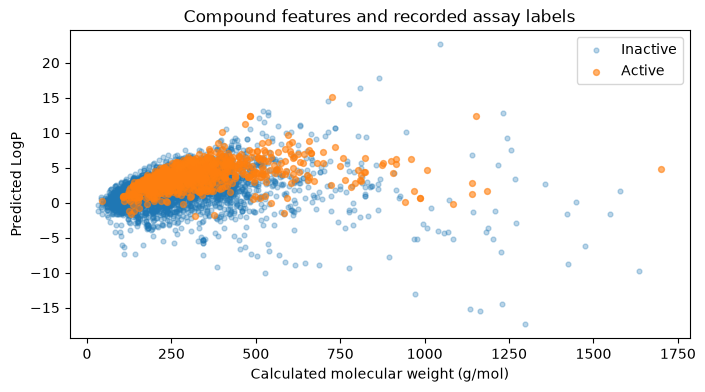

In [10]:
inactive = labels == "Inactive"
active = labels == "Active"
plt.figure(figsize=(8, 4))
plt.scatter(features.loc[inactive, "Mass"], features.loc[inactive, "LogP"], label="Inactive", alpha=0.3, s=12)
plt.scatter(features.loc[active, "Mass"], features.loc[active, "LogP"], label="Active", alpha=0.6, s=18)
plt.xlabel("Calculated molecular weight (g/mol)")
plt.ylabel("Predicted LogP")
plt.title("Compound features and recorded assay labels")
plt.legend()
plt.show()

### Stop and explain 1

What do Mass and LogP describe? Are they measured assay results?
Explain why an unusual descriptor pattern is a different question from assay activity.

Suggested answer: Mass is calculated molecular weight; LogP is a predicted
partition property. Both come from the recorded chemical structure. An unusual
pattern concerns the distribution of these descriptors, whereas activity is
a recorded experimental outcome in SR-MMP. One does not define the other.

## 3. Choose the reference group

X means features and y means assay labels. Use the same 80/20 split
as Foundations: 4,643 training records and 1,161 test records.
`random_state=42` makes it repeatable; `stratify=labels` keeps similar class
proportions. Labels help form the split but do not teach this detector.

The reference group is the whole training group, including Active and
Inactive compounds. Here “usual” means familiar descriptor patterns, not
Inactive or safe. If you did strawberry Applications, its reference group
was labelled Strawberry; this question needs a different reference group.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training reference samples:", len(X_train))
print("Test samples:", len(X_test))

Training reference samples: 4643
Test samples: 1161


This returns to the original Foundations training group, including the
validation records from Evaluation. The detector and flagging setting are
fixed in advance, so we are not using validation to compare alternatives.

### Stop and explain 2

Why does the reference group include both assay classes? Why should the
test compounds be excluded while the detector learns familiar patterns?

Suggested answer: We want to learn the descriptor patterns of the known
training compounds, not to redefine Active as abnormal. Including both
classes makes that reference explicit. Keeping test compounds out allows
us to check unfamiliar records without first teaching them to the detector.

## 4. Teach one outlier detector

An isolation forest makes many random questions about the descriptors.
Unusual records can often be separated from most reference examples with
fewer questions. The forest combines this information to flag measurements.
Evaluation's random forest learned class labels; this forest does a different job.

`fit(X_train)` receives features, not assay labels. The fixed teaching setting
`contamination=0.05` places a boundary so that about 5% of the training
reference records are flagged. It does not measure the fraction of toxic
compounds or require that 5% of future records be flagged. Keep it unchanged.

In [12]:
detector = IsolationForest(contamination=0.05, random_state=42)
detector.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


### Stop and explain 3

Does 0.05 mean that 5% of compounds are toxic? Must 5% of the test group
be flagged? Explain what this setting actually controls.

Suggested answer: No to both. The setting determines a flagging boundary
using the training descriptor patterns. It is not an assay activity rate
or a toxicity measurement. A new group may contain a different fraction
of unusual descriptor patterns.

## 5. Flag records excluded from training

`predict` uses the eight test features without their assay labels. It returns
`-1` for flagged records and `1` for the rest. `== -1` makes a simple flag:
True means flagged, False means not flagged. `sum()` counts True flags.

In [13]:
flags = detector.predict(X_test) == -1
review = pd.DataFrame({"Flagged": flags}, index=X_test.index)
print("Compounds checked:", len(review))
print("Flagged for review:", review["Flagged"].sum())
review.head()

Compounds checked: 1161
Flagged for review: 57


,Flagged
4867,False
6532,False
924,False
3012,False
5043,False


Each dot below is one test compound. The axes show molecular weight and
predicted LogP; orange points are flagged. The detector used all eight
descriptors, so separation in this two-feature view need not be obvious.
Larger values do not automatically mean more toxic compounds.

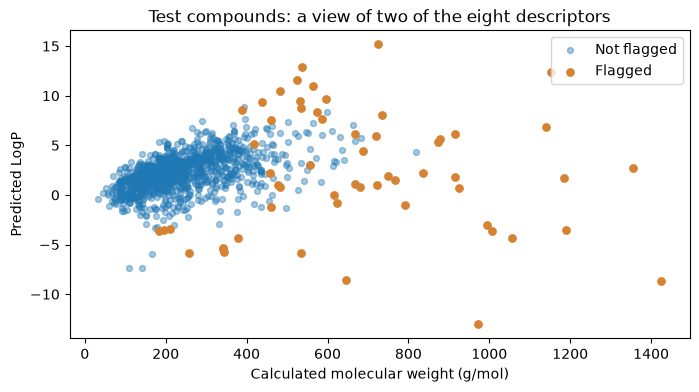

In [14]:
plt.figure(figsize=(8, 4))
plt.scatter(X_test.loc[~flags, "Mass"], X_test.loc[~flags, "LogP"],
            label="Not flagged", alpha=0.4, s=18)
plt.scatter(X_test.loc[flags, "Mass"], X_test.loc[flags, "LogP"],
            label="Flagged", color="#D58232", s=28)
plt.xlabel("Calculated molecular weight (g/mol)")
plt.ylabel("Predicted LogP")
plt.title("Test compounds: a view of two of the eight descriptors")
plt.legend()
plt.show()

Inspect the first flagged row in the test table. The table compares its
descriptor values with the training averages. `loc` selects the row;
`mean()` gives an average per feature. These averages are visual reference
values, not acceptance limits. Do not compare absolute differences across
descriptors with different units. One example does not represent all flags.

In [15]:
example_id = review.loc[review["Flagged"]].index[0]
comparison = pd.DataFrame({
    "Training average": X_train.mean(),
    "Flagged example": X_test.loc[example_id]
})
print("Example source ID:", data.loc[example_id, "mol_id"])
comparison.round(2)

Example source ID: TOX26696


,Training average,Flagged example
Mass,261.99,680.74
LogP,2.18,0.82
H_donors,1.22,5.00
H_acceptors,3.38,11.00
Polar_area,58.56,245.03
Rotatable_bonds,4.17,13.00
Aromatic_rings,0.98,3.00
Heavy_atoms,17.59,47.00


### Stop and explain 4

Compare the example's Mass and Polar_area with their own training averages.
Does this table prove that the structure is wrong, or that the compound is toxic?
Give one useful follow-up check.

Suggested answer for TOX26696: Its Mass is 680.74 g/mol
versus a training average of 261.99, and its Polar_area is
245.03 Å² versus 58.56. These differences help describe
the record but do not explain the complete forest decision. Check the source
structure, fragments and descriptor calculation; an unusual but correct
compound may simply need additional experimental information.

## 6. Reveal the assay labels

Add the known test labels only after flagging. `crosstab` counts flagged
and unflagged records for each assay class. As in the earlier mistake tables,
rows are reference labels. Here columns are Not flagged and Flagged,
not predicted assay classes. Active is not a ground-truth label for outliers.

In [16]:
review["Reference"] = y_test
counts = pd.crosstab(review["Reference"], review["Flagged"])
counts = counts.rename(columns={False: "Not flagged", True: "Flagged"})
counts = counts.reindex(["Inactive", "Active"])
counts

Flagged,Not flagged,Flagged
Reference,,
Inactive,932,45
Active,172,12


The bars show the same counts. The classes have different sizes: compare
each flagged count with the total of its own row, rather than comparing
bar heights alone. This is not a classification accuracy chart.

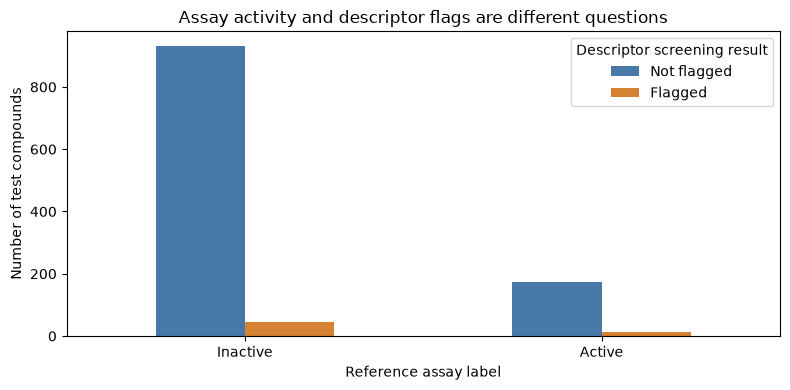

In [17]:
counts.plot.bar(color=["#4878A8", "#D58232"], rot=0, figsize=(8, 4))
plt.ylabel("Number of test compounds")
plt.xlabel("Reference assay label")
plt.title("Assay activity and descriptor flags are different questions")
plt.legend(title="Descriptor screening result")
plt.tight_layout()
plt.show()

### Stop and explain 5

How many Active and Inactive compounds were flagged? How many Active
compounds were not flagged? Why are these not false-positive and
false-negative counts for an assay classifier?

Suggested answer for the saved run: 12 Active and
45 Inactive records were flagged; 172
Active records were not flagged. The detector learned descriptor patterns,
not assay activity. Neither Active nor Inactive defines whether a descriptor
pattern is unusual, so these counts are not classifier error counts.

## 7. Plan the follow-up

An unflagged compound can still be Active in SR-MMP. A flagged compound
can be Inactive. An assay prediction and an outlier flag answer different
questions; neither certifies human safety.

The test group was used earlier in the series. Reuse here is a classroom
demonstration, not fresh independent validation. New chemical families
require further checks before routine use of these models.

### Stop and explain 6

A colleague says, “We can treat every unflagged compound as safe.”
Write two or three sentences explaining what the results support and
what experimental follow-up is still needed.

Example: Unflagged means familiar descriptor patterns, not safe:
172 unflagged test compounds were Active in this assay.
Review flagged structures and calculations, and use suitable experimental
assays to investigate biological activity. Even an Inactive SR-MMP result
does not settle other toxicity endpoints or real-world exposure risks.

## Data and reuse

These practicals use the public DeepChem Tox21 CSV, not a new experimental
dataset. Of 7,831 source records, 2,021 have no SR-MMP result and six more
have structures unreadable with the fixed RDKit version. The 5,804 retained
records contain 4,886 Inactive and 918 Active results. Instructors checked
that no identical canonical structure is repeated in this retained subset.
Different structures can still have identical values for these eight descriptors.

These random teaching splits are not DeepChem's default scaffold split:
related chemical families can occur in both training and test groups.
They do not establish performance on unfamiliar chemical families. No
fragments, charges or salts are removed from the recorded structures.

- [Tox21 challenge: assay tasks and original data context](https://tripod.nih.gov/tox21/challenge/about.jsp).
- [DeepChem Tox21 loader and source-file address](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/tox21_datasets.py).
- [RDKit molecular descriptor documentation](https://www.rdkit.org/docs/GettingStartedInPython.html#list-of-available-descriptors).

We read DeepChem's public data file directly with pandas and calculate
descriptors with RDKit. Installing the DeepChem Python package is not
required. These exercises do not reproduce the Tox21 challenge benchmark.
An assay prediction or an outlier flag cannot certify human safety.